$\newcommand{\P}{\mathbf P}$
$\newcommand{\cov}{\operatorname{Cov}}$
$\newcommand{\E}{\mathbf E}$
$\newcommand{\var}{\operatorname{Var}}$
$\newcommand{\1}{\mathbf 1}$
$\newcommand{\R}{\mathbb R}$
$\newcommand{\Exp}{\text{Exp}}$
$\newcommand{\Pois}{\text{Poisson}}$
$\newcommand{\Ber}{\text{Bernoulli}}$

**Mill's inequality.** We may write Mill's inequality as
$$ \P(Z > |t|) \le 2 \cdot \frac{1}{\sqrt{2\pi}} \frac{e^{-t^2/2}}{t} $$

#4. Exercises

**Exercise 4.1.** Let $X \sim \Exp(\beta)$. Using Chebyshev's inequality, for $k > 1$,
$$ \P(|X - \beta| \ge k \beta)  \le k^{-2}$$
The actual value is
$$ \P(|X - \beta| \ge k \beta) = \int_{(k+1)\beta}^{\infty} f_X(x) \, dx = e^{-(k+1)}$$

**Exercise 4.2.** Let $X \sim \Pois(\lambda)$. Using Chebyshev's inequality
$$
\begin{align*}
\P(X \ge 2\lambda) &= \P(X - \lambda \ge \lambda) \\
&\le \P(|X - \lambda| \ge \lambda) \\
&\le \frac{\lambda}{\lambda^2} = \frac 1\lambda
\end{align*}
$$

**Exercise 4.3.** Let $X_1,\dots,X_n \sim \Ber(p)$ be IID. Using Chebyshev's inequality,
$$ \P(|\bar X_n - p| > ɛ) \le \frac{p(1-p)/n}{ɛ^2} = \frac{p(1-p)}{nɛ^2}$$
Using Hoeffding's inequality,
$$ \P(|\bar X_n - p| > ɛ) \le 2e^{-2nɛ^2} $$

**Exercise 4.4.** Let $X_1,\dots,X_n \sim \Ber(p)$ be IID.

(a) Using Hoeffding's inequality, if
$$ a_n = \sqrt{\frac{1}{2n} \log\left(\frac 2 \alpha\right)} $$
and $C_n = [\bar X_n -a_n, \bar X_n + a_n]$, then
$$ \P(\text{$C_n$ contains $p$}) \ge 1-\alpha$$

In [1]:
#(b)
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

p = 0.4
alpha = 0.05

for n in [10, 100, 1000, 10_000]:
    an = np.sqrt( np.log(2/alpha) / (2*n) )
    c1 = p + an

    x = rng.binomial(1,p,size=(999,n))
    x=x.mean(axis=1)
    display(((x <= p + an) & (p - an <= x)).mean())

np.float64(0.997997997997998)

np.float64(0.993993993993994)

np.float64(0.994994994994995)

np.float64(0.995995995995996)

In [2]:
#(c) If we want the length of the interval to be $\le 0.05$, then n \ge
0.5 * np.log(2 / alpha) / (0.05/2)**2

np.float64(2951.1035632911485)

**Exercise 4.5.** Proof of Mill's inequality.

We need to show that
$$ \frac{1}{\sqrt{2\pi}}\int_t^\infty  e^{-x^2 / 2} \, dx \le \frac{1}{\sqrt{2\pi}} \frac{e^{-t^2/2}}{t},$$
that is,
$$ \int_t^\infty t e^{-x^2 / 2} \, dx \le e^{-t^2/2}.$$
The left-hand side is
\begin{align*} \int_t^\infty  te^{-x^2 / 2} \, dx
&\le \int_t^\infty  x e^{-x^2 / 2} \, dx & (*)\\
&=\frac 12 \int_{t^2}^\infty e^{-u/2} du \\
&= e^{-t^2/2}.
\end{align*}
The idea for $(*)$ is based on [this](https://math.stackexchange.com/questions/723041/mills-inequality-on-normal-distribution$0).


**Exercise 4.6.** Let $Z \sim N(0,1)$. We know that
\begin{align*}
\sum_{k=0}^\infty \E (Z^k)\frac{t^k}{k!} = e^{t^2/2} = \sum_{k=0}^\infty \frac{1}{k!}\frac{t^{2k}}{2^k} =  \sum_{k=0}^\infty \frac{1}{(2k)!} \frac{(2k)!}{k!}\frac{t^{2k}}{2^k}.
\end{align*}
So $\E(Z^2) = 1$ and $\E(Z^4) = 3$. To compute the absolute moments for $\alpha$ odd,  
\begin{align*}
\E(|Z|^\alpha) &= 2\cdot \frac{1}{\sqrt{2\pi}} \int_0^\infty x x^{\alpha-1} e^{-x^2/2} \, dx \\
&= \frac{1}{\sqrt{2\pi}}  \int_0^\infty u^{(\alpha - 1)/2} e^{-u/2}\, du \\
&= 2\cdot \frac{1}{\sqrt{2\pi}} \cdot 2^{(\alpha-1)/2}\int_0^\infty v^{(\alpha - 1)/2} e^{-v}\, dv \\
&=  \frac{2^{\alpha/2}}{\sqrt{\pi}} \int_0^\infty v^{(\alpha - 1)/2} e^{-v}\, dv \\
&= \frac{2^{\alpha/2}}{\sqrt{\pi}}\Gamma\left(\frac{\alpha+1}{2} \right).
\end{align*}
So $\E |Z| = \sqrt {\frac 2 \pi}$, $\E|Z|^3 = 2 \sqrt \frac 2 \pi$, and $\E|Z|^5 = 8 \sqrt \frac 2 \pi$.

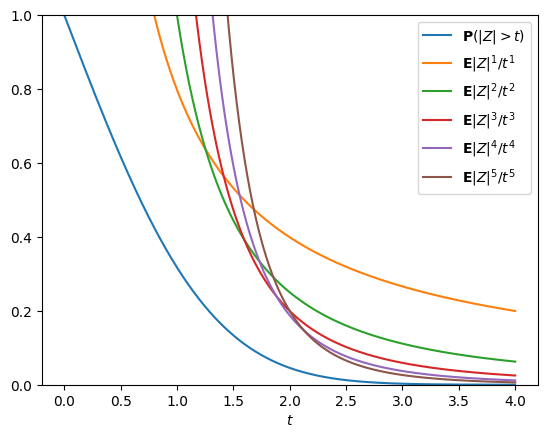

In [3]:
from scipy.stats import norm
x = np.linspace(0,4,1000)
gammas = np.array([np.nan, np.sqrt(2/np.pi), 1, 2 * np.sqrt(2/np.pi), 3, 8 * np.sqrt(2/np.pi)])
plt.plot(x, 2 * norm.sf(x), label=r'$\mathbf{P}(|Z| > t)$')
for i in range(1, 6):
    s = rf'$\mathbf{{E}}|Z|^{{{i}}}/t^{{{i}}}$'
    plt.plot(x, gammas[i]/ np.maximum(x, 0.001) ** i, label=s)
plt.xlabel('$t$')
plt.ylim(0,1)
plt.legend()
plt.show()


**Exercise 4.7.** Let $X_1, \dots, X_n \sim N(0,1)$ be IID and $\bar X = \frac 1n\sum X_i$. Then $\bar X \sim N(0,1/n) $ and using Mill's inequality
\begin{align*}
\P(|\bar X| > t) &= \P ( |N(0,1) | > \sqrt n t ) \\
&\le \sqrt{\frac{2}\pi} \frac{e^{-nt^2/2}}{\sqrt n t}.
\end{align*}
We compare this to the Chebyshev bound
\begin{align*}
\P( |\bar X |  > t) &\le \frac{\var(\bar X)}{t^2} \\
&= \frac 1{nt^2}.
\end{align*}